# Install the Required packages

In [1]:
# Pandas package

!pip install pandas
import pandas as pd

# Matplotlib package installation

!pip install matplotlib
import matplotlib.pyplot as plt

# Seaborn package installation

!pip install seaborn
import seaborn as sns


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Data Collection

In [2]:
df = pd.read_excel(r"C:\Users\Blesso\Desktop\Analytics Avenue\Projects\Data Science\Raushbyte\Excel Data Analysis\Data_Science.xlsx")

# Data Overview

In [4]:
df.head()

,Transaction_ID,Customer_Name,City,Department,Product,Quantity,Unit_Price,Revenue,Expense,Profit,Customer_Rating,Customer_Feedback,Employee_Performance_Score,Payment_Method,Purchase_Date
0,TXN00001,Maria Dominguez,Hyderabad,HR,Headphones,2,69623,139246,79676,59570,1,Poor,98,Net Banking,2024-10-23
1,TXN00002,Jasmine Wells,Mumbai,Sales,Keyboard,3,5478,16434,7198,9236,4,Excellent,53,Net Banking,2024-06-04
2,TXN00003,Sherri Brown,Delhi,Finance,Tablet,8,2629,21032,12831,8201,2,Average,76,Net Banking,2024-11-22
3,TXN00004,Dr. Lisa Garcia,Mumbai,IT,Mobile,5,49088,245440,131238,114202,2,Good,86,Card,2024-03-28
4,TXN00005,Kelly Carpenter,Delhi,IT,Smartwatch,10,17066,170660,104544,66116,4,Poor,90,UPI,2024-02-06


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Transaction_ID              8000 non-null   object
 1   Customer_Name               8000 non-null   object
 2   City                        8000 non-null   object
 3   Department                  8000 non-null   object
 4   Product                     8000 non-null   object
 5   Quantity                    8000 non-null   int64 
 6   Unit_Price                  8000 non-null   int64 
 7   Revenue                     8000 non-null   int64 
 8   Expense                     8000 non-null   int64 
 9   Profit                      8000 non-null   int64 
 10  Customer_Rating             8000 non-null   int64 
 11  Customer_Feedback           8000 non-null   object
 12  Employee_Performance_Score  8000 non-null   int64 
 13  Payment_Method              8000 non-null   obje

In [6]:
df.describe()

,Quantity,Unit_Price,Revenue,Expense,Profit,Customer_Rating,Employee_Performance_Score
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,5.489875,39986.185250,220579.671250,143603.016125,76976.655125,2.974000,75.047500
std,2.867564,22816.835733,184033.861201,127191.071525,76480.501085,1.406706,14.809057
min,1.000000,512.000000,556.000000,335.000000,180.000000,1.000000,50.000000
25%,3.000000,19996.000000,67909.500000,43332.000000,20328.500000,2.000000,62.000000
50%,5.000000,39939.500000,166532.000000,105032.500000,51473.500000,3.000000,75.000000
75%,8.000000,59629.750000,335917.250000,212453.000000,109249.500000,4.000000,88.000000
max,10.000000,79993.000000,798410.000000,714389.000000,478595.000000,5.000000,100.000000


In [7]:
df.shape

(8000, 15)

# Data Quality

In [13]:
# Missing values

df.isnull().sum()

Transaction_ID                0
Customer_Name                 0
City                          0
Department                    0
Product                       0
Quantity                      0
Unit_Price                    0
Revenue                       0
Expense                       0
Profit                        0
Customer_Rating               0
Customer_Feedback             0
Employee_Performance_Score    0
Payment_Method                0
Purchase_Date                 0
dtype: int64

In [11]:
# Checking Duplicates

df.duplicated().sum()

0

In [14]:
df.nunique()

Transaction_ID                8000
Customer_Name                 7612
City                             6
Department                       6
Product                          7
Quantity                        10
Unit_Price                    7608
Revenue                       7905
Expense                       7885
Profit                        7795
Customer_Rating                  5
Customer_Feedback                4
Employee_Performance_Score      51
Payment_Method                   4
Purchase_Date                  501
dtype: int64

# Data Preprocessing

In [15]:
# Convert the data type of Purchase_Date column

df['Purchase_Date'] = pd.to_datetime(df['Purchase_Date'])

# EDA

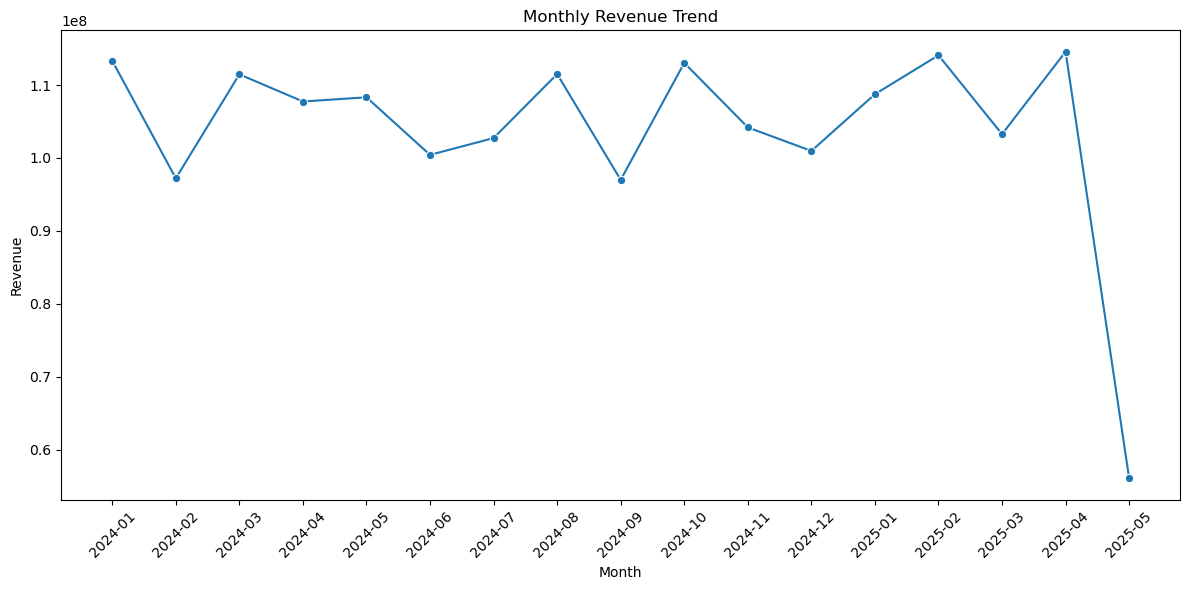

In [19]:
# Extract month
df['Month'] = df['Purchase_Date'].dt.to_period('M')

# Calculate monthly revenue
monthly_revenue = (
    df.groupby('Month')['Revenue'].sum().reset_index()
)

# Convert Period to string for plotting
monthly_revenue['Month'] = monthly_revenue['Month'].astype(str)

# Plot
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_revenue,
    x='Month',
    y='Revenue',
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

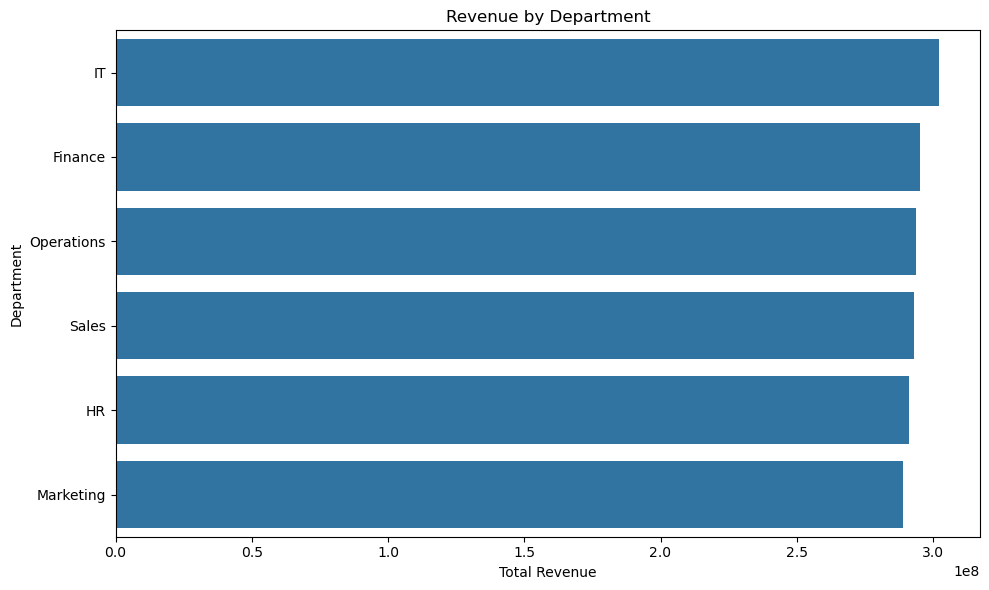

In [22]:
# Revenue by department

department_revenue = (
    df.groupby('Department')['Revenue']
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=department_revenue,
    x='Revenue',
    y='Department'
)

plt.title('Revenue by Department')
plt.xlabel('Total Revenue')
plt.ylabel('Department')
plt.tight_layout()
plt.show()

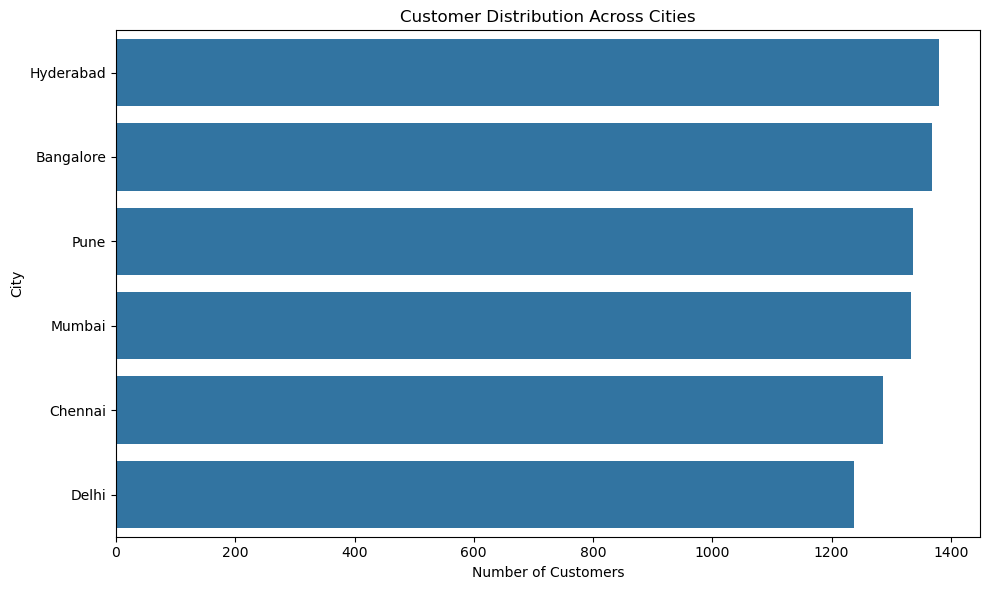

In [23]:
# Customer Distribution across city

customer_city = (
    df.groupby('City')['Customer_Name']
      .nunique()
      .sort_values(ascending=False)
      .reset_index(name='Customer_Count')
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=customer_city,
    x='Customer_Count',
    y='City'
)

plt.title('Customer Distribution Across Cities')
plt.xlabel('Number of Customers')
plt.ylabel('City')
plt.tight_layout()
plt.show()

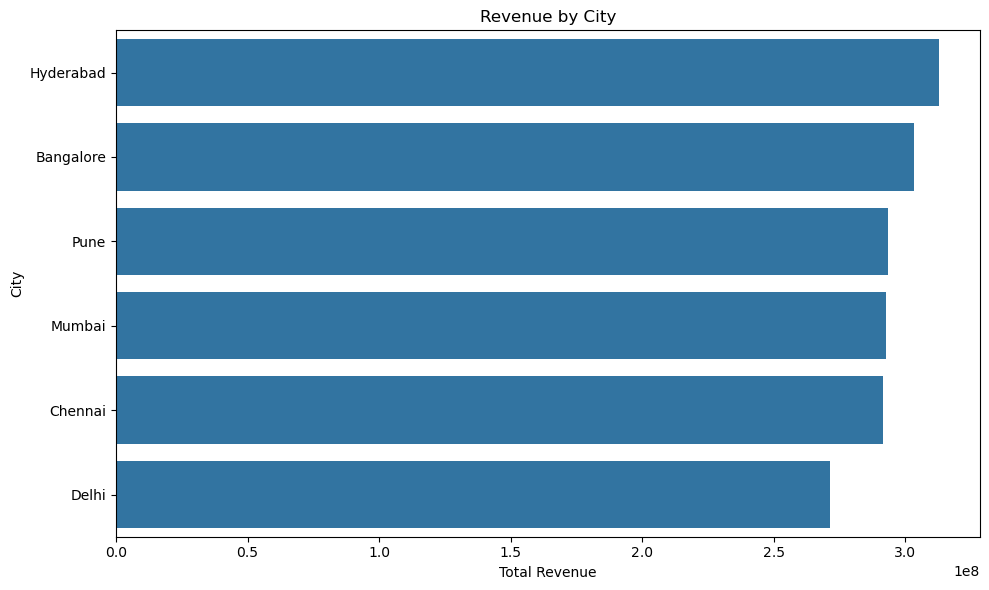

In [36]:
# Revenue by city

city_revenue = (
    df.groupby('City')['Revenue']
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=city_revenue,
    x='Revenue',
    y='City'
)

plt.title('Revenue by City')
plt.xlabel('Total Revenue')
plt.ylabel('City')
plt.tight_layout()
plt.show()

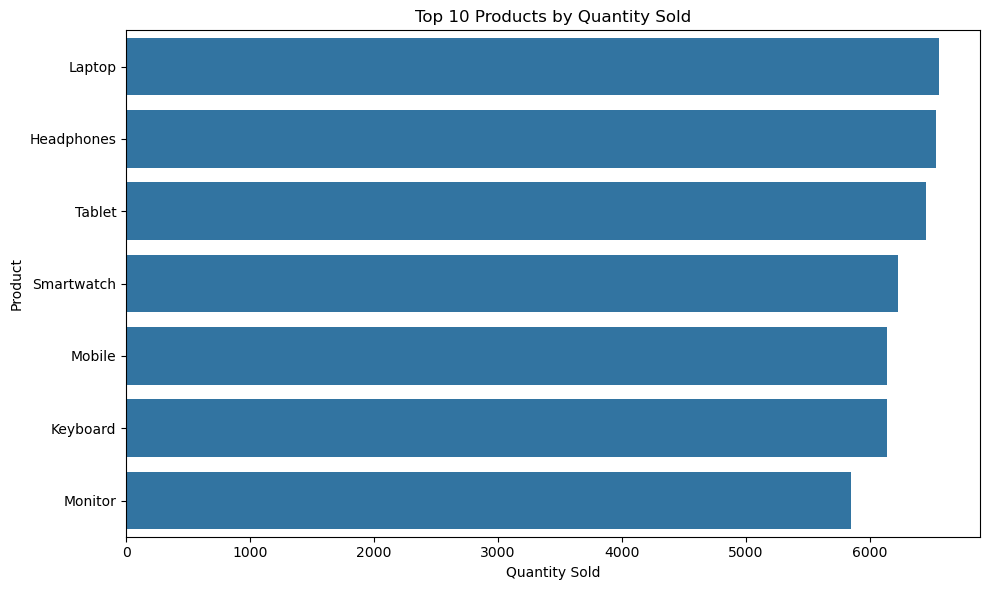

In [25]:
# Product sold in large quantity

product_quantity = (
    df.groupby('Product')['Quantity']
      .sum()
      .sort_values(ascending=False)
      .head(10)
      .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=product_quantity,
    x='Quantity',
    y='Product'
)

plt.title('Top 10 Products by Quantity Sold')
plt.xlabel('Quantity Sold')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

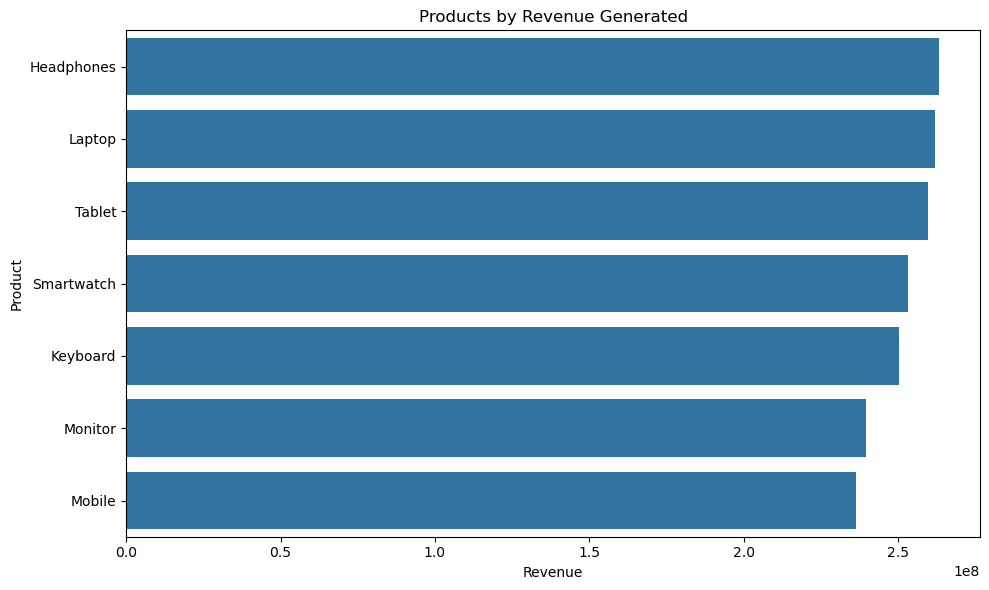

In [27]:
# Revenue by product

product_revenue = (
    df.groupby('Product')['Revenue']
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=product_revenue,
    x='Revenue',
    y='Product'
)

plt.title('Products by Revenue Generated')
plt.xlabel('Revenue')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

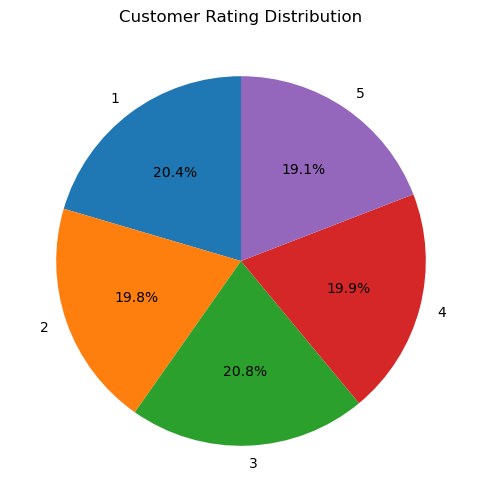

In [29]:
# Customer ratings distributions

rating_distribution = (
    df['Customer_Rating']
      .value_counts()
      .sort_index()
)

plt.figure(figsize=(6, 6))

plt.pie(
    rating_distribution.values,
    labels=rating_distribution.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Rating Distribution')
plt.show()

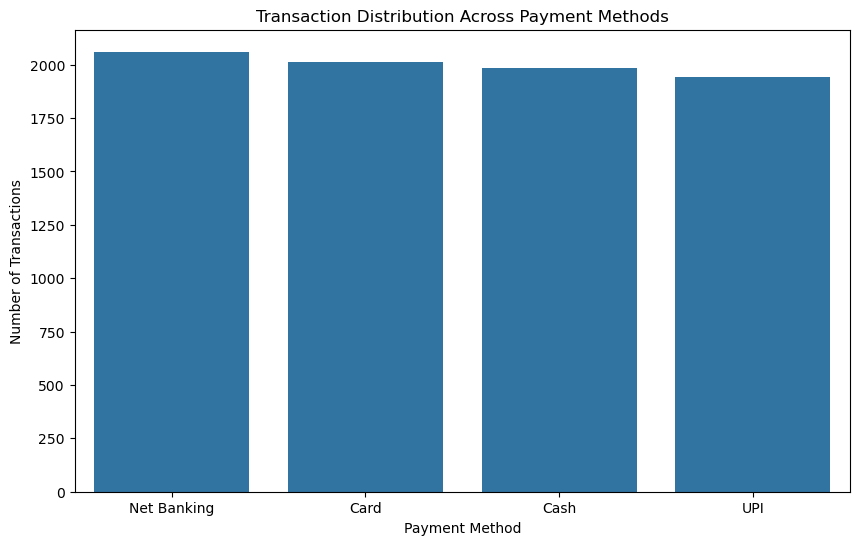

In [32]:
# Payment Distribution

payment_distribution = (
    df['Payment_Method']
      .value_counts()
      .reset_index()
)

payment_distribution.columns = ['Payment_Method', 'Transaction_Count']

plt.figure(figsize=(10, 6))

sns.barplot(
    data=payment_distribution,
    x='Payment_Method',
    y='Transaction_Count'
)

plt.title('Transaction Distribution Across Payment Methods')
plt.xlabel('Payment Method')
plt.ylabel('Number of Transactions')
plt.show()

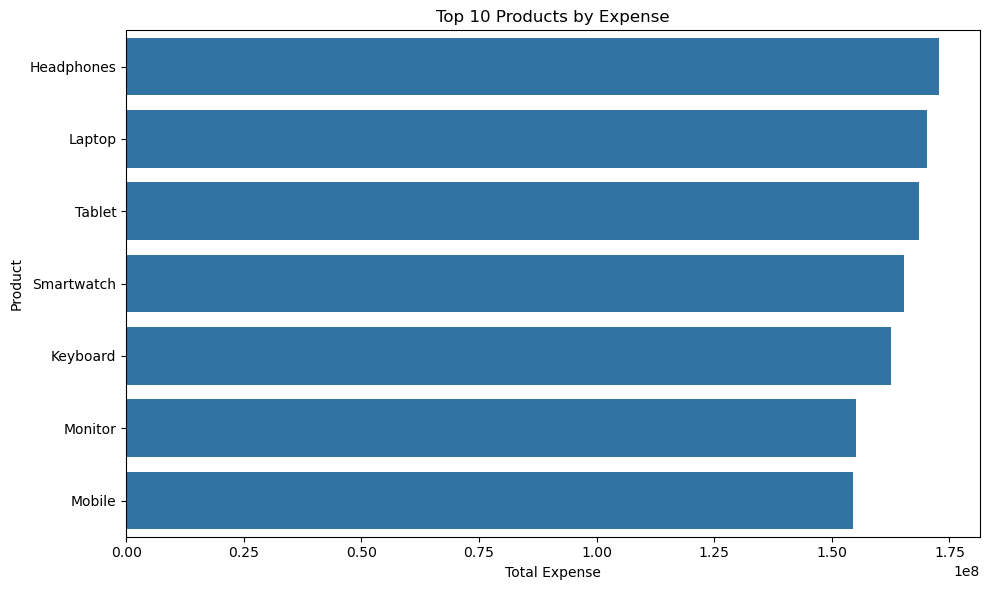

In [33]:
# Product Expendicture

product_expense = (
    df.groupby('Product')['Expense']
      .sum()
      .sort_values(ascending=False)
      .head(10)
      .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=product_expense,
    x='Expense',
    y='Product'
)

plt.title('Top 10 Products by Expense')
plt.xlabel('Total Expense')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

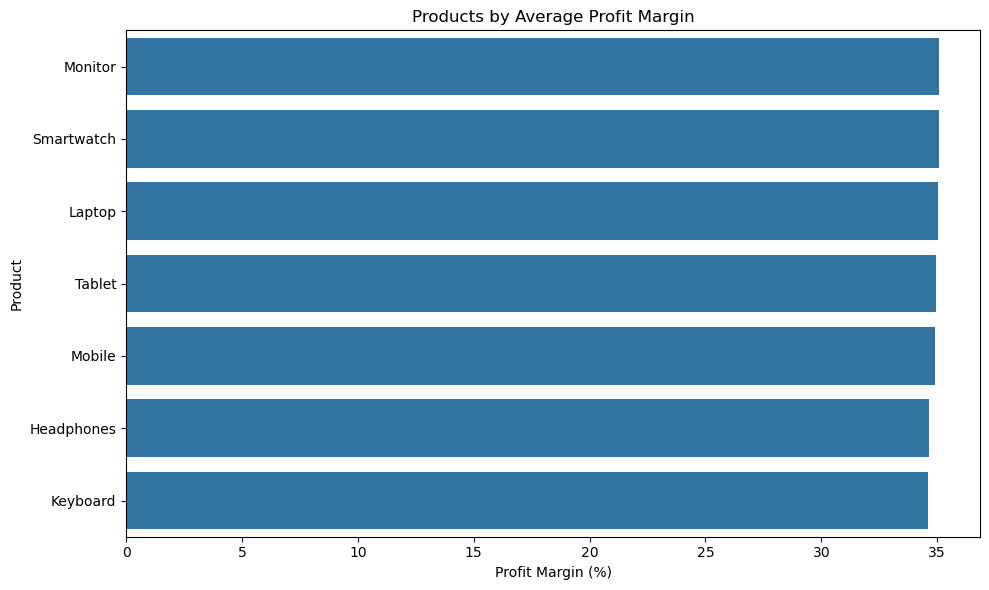

In [38]:
# Profit margin for each products

df['Profit_Margin'] = (df['Profit'] / df['Revenue']) * 100

product_margin = (
    df.groupby('Product')['Profit_Margin']
      .mean()
      .sort_values(ascending=False)
      .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=product_margin,
    x='Profit_Margin',
    y='Product'
)

plt.title('Products by Average Profit Margin')
plt.xlabel('Profit Margin (%)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()